In [5]:
# import packages
from pathlib import Path
import pandas as pd
import geopandas as gpd
import seaborn as sns


In [6]:
# file path to import data
root_fldr = Path.cwd().parent
raw_fldr = root_fldr / 'data' / 'raw' 
processed_fldr = root_fldr / 'data' / 'processed'
fire_shp= raw_fldr / 'cal_fire_historical_data' / 'California_Historic_Fire_Perimeters_-6302641808644124224.zip'

In [7]:
# Read the shapefile
wildfires_gdf = gpd.read_file(filename = fire_shp)
wildfires_gdf.head()

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,ALARM_DATE,CONT_DATE,CAUSE,C_METHOD,OBJECTIVE,GIS_ACRES,COMMENTS,COMPLEX_NA,IRWINID,FIRE_NUM,COMPLEX_ID,DECADES,geometry
0,2025,CA,USF,LPF,GIFFORD,00002181,2025-08-01,2025-10-14,14,3,1,131614.0,NaN,NaN,{08A6358F-8301-4093-9988-E265C8F6F0A9},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13401376.178 4203562.931, -13..."
1,2025,CA,USF,LPF,MADRE,00001817,2025-07-02,2025-07-26,14,7,1,80779.1,NaN,NaN,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},NaN,NaN,2020-2025,"POLYGON ((-13363729.916 4190093.666, -13363730..."
2,2025,CA,USF,SNF,GARNET,00001684,2025-08-24,2025-10-23,1,3,1,60019.2,NaN,NaN,{68B988A1-C190-4F0C-9BEA-A658D389D167},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13246213.777 4426752.325, -13..."
3,2025,CA,CDF,FKU,SALT,00018739,2025-09-02,2025-09-17,1,7,1,25553.5,Park incident clipped out per BEU,NaN,{7F4A1474-6439-44F3-8F0D-083DCFD33639},NaN,NaN,2020-2025,"POLYGON ((-13397839.121 4293483.6, -13397810.1..."
4,2025,CA,CDF,LDF,PALISADES,00000738,2025-01-07,2025-01-31,14,7,1,23448.9,NaN,NaN,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13193558.265 4032826.468, -13..."


In [8]:
# link to metadata and documentation here: https://calfire-forestry.maps.arcgis.com/home/item.html?id=a31aa1efe1d6466f8530b501c30ab00a#overview

#wildifre cause variable clarification 
wildfire_cause = {
    1: 'Lightning',
    2: 'Equipment Use',
    3: 'Smoking',
    4: 'Campfire',
    5: 'Debris',
    6: 'Railroad',
    7: 'Arson',
    8: 'Playing with Fire',
    9: 'Miscellaneous',
    10: 'Vehicle',
    11: 'Electrical Power',
    12: 'Firefighter Training',
    13: 'Non-Firefighter Training',
    14: 'Unknown/Unidentified',
    15: 'Structure',
    16: 'Aircraft',
    17: 'Volcanic',
    18: 'Escaped Prescribed Burn',
    19: 'Illegal Alien Campsite',
}

agency_domains = {
    'BIA': 'USDI Bureau of Indian Affairs',
    'BLM': 'Bureau of Land Management',
    'CDF': 'California Department of Forestry and Fire Protection',
    'CCO': 'Contract County',
    'CSP': 'California State Parks',
    'DOD': 'Department of Defense',
    'FWS': 'USDI Fish and Wildlife Service',
    'LRA': 'Local Responsibility Area',
    'NOP': 'No Protection',
    'NPS': 'National Park Service',
    'PVT': 'Private',
    'USF': 'USDA Forest Service',
    'OTH': 'Other',
}


In [9]:
#adding columns for clearer description of initial columns 
wildfires_gdf['cause_description'] = wildfires_gdf['CAUSE'].map(wildfire_cause)
wildfires_gdf['agency_description'] = wildfires_gdf['AGENCY'].map(agency_domains)
wildfires_gdf.head()

,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,INC_NUM,ALARM_DATE,CONT_DATE,CAUSE,C_METHOD,...,GIS_ACRES,COMMENTS,COMPLEX_NA,IRWINID,FIRE_NUM,COMPLEX_ID,DECADES,geometry,cause_description,agency_description
0,2025,CA,USF,LPF,GIFFORD,00002181,2025-08-01,2025-10-14,14,3,...,131614.0,NaN,NaN,{08A6358F-8301-4093-9988-E265C8F6F0A9},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13401376.178 4203562.931, -13...",Unknown/Unidentified,USDA Forest Service
1,2025,CA,USF,LPF,MADRE,00001817,2025-07-02,2025-07-26,14,7,...,80779.1,NaN,NaN,{1AB682F7-CC0F-4DCE-87A4-FA4A9B67AB05},NaN,NaN,2020-2025,"POLYGON ((-13363729.916 4190093.666, -13363730...",Unknown/Unidentified,USDA Forest Service
2,2025,CA,USF,SNF,GARNET,00001684,2025-08-24,2025-10-23,1,3,...,60019.2,NaN,NaN,{68B988A1-C190-4F0C-9BEA-A658D389D167},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13246213.777 4426752.325, -13...",Lightning,USDA Forest Service
3,2025,CA,CDF,FKU,SALT,00018739,2025-09-02,2025-09-17,1,7,...,25553.5,Park incident clipped out per BEU,NaN,{7F4A1474-6439-44F3-8F0D-083DCFD33639},NaN,NaN,2020-2025,"POLYGON ((-13397839.121 4293483.6, -13397810.1...",Lightning,California Department of Forestry and Fire Pro...
4,2025,CA,CDF,LDF,PALISADES,00000738,2025-01-07,2025-01-31,14,7,...,23448.9,NaN,NaN,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},NaN,NaN,2020-2025,"MULTIPOLYGON (((-13193558.265 4032826.468, -13...",Unknown/Unidentified,California Department of Forestry and Fire Pro...


<Axes: xlabel='Easting [metre]', ylabel='Northing [metre]'>

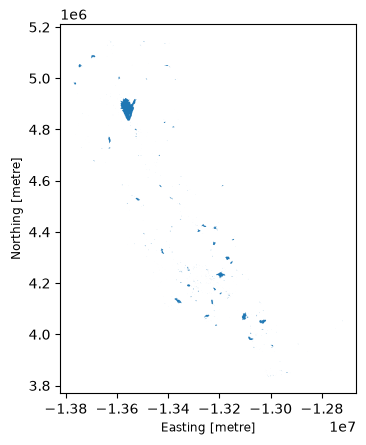

In [10]:
fires_2024 = wildfires_gdf.query('YEAR_ == 2024')
fires_2024.plot()

In [ ]:
try:
    import contextily as ctx
except ImportError:
    %conda install contextily
    import contextily as ctx 

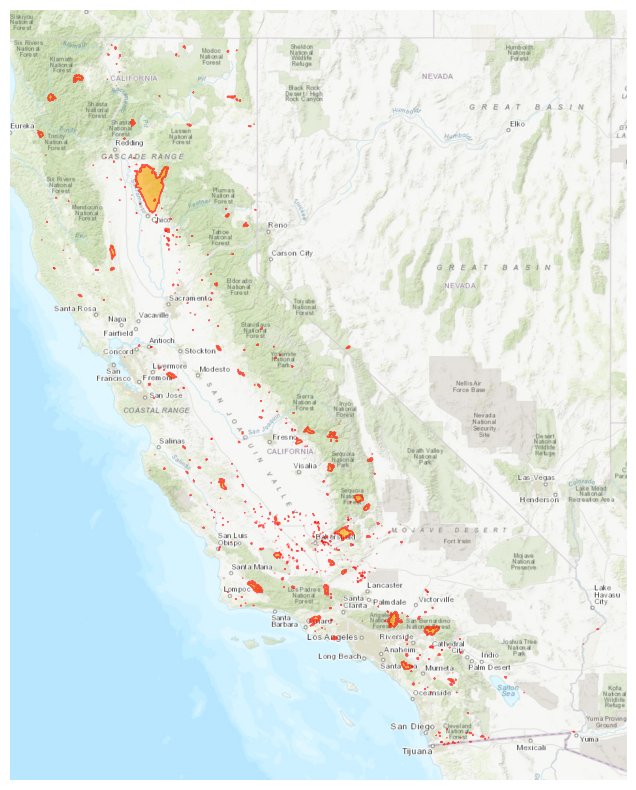

In [15]:
import contextily as ctx

basemap_url = 'https://server.arcgisonline.com/ArcGIS/rest/services/World_Topo_Map/MapServer/tile/{z}/{y}/{x}'

fires_2024 = wildfires_gdf.query('YEAR_ == 2024')

fires_plot = fires_2024.to_crs(epsg=3857).plot(
    figsize=(10, 10),
    color='orange',
    edgecolor='red',
    alpha=0.6
)

ctx.add_basemap(fires_plot, source=basemap_url)
#fires_plot.set_title('2024 California Wildfires')
fires_plot.set_axis_off()
